# 04 ¿Cuándo entrar al mercado?

**Proyecto:** Análisis de estrategias de inversión en el S&P 500

Las calculadoras de internet te dicen cuánto habrías ganado invirtiendo en una fecha concreta. Pero eso depende mucho de la suerte: no es lo mismo empezar justo antes de una caída que después.

En este notebook comparo dos formas de invertir 12.000 dólares:

Meterlo todo de golpe el primer día.

Repartirlo en 12 aportaciones de 1.000 dólares, una cada mes.

Y en vez de probar con una sola fecha, lo pruebo empezando en todos los meses posibles desde 2016, para ver cuál de las dos estrategias ganó más veces.

### Datos

Uso el archivo indice_limpio.csv de Data/Processed, con los precios diarios del índice.

## 1. Preparo los datos por meses
El notebook detecta automáticamente si se está ejecutando en Google Colab o en local, de forma que cualquier persona pueda ejecutarlo sin modificar las rutas.

In [1]:
# Importo pandas para trabajar con tablas
import pandas as pd
# Importo os para poder crear carpetas si no existen
import os

# Compruebo dónde se está ejecutando el notebook
try:
    # Si estoy en Colab, conecto mi Drive y uso mi carpeta
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_PROYECTO = "/content/drive/MyDrive/PORTFOLIO MARCOS GUERRERO SANCHEZ/analisis-estrategias-inversion/"
except ImportError:
    # Si no estoy en Colab, uso la carpeta donde esté el proyecto descargado
    # El ../ sube un nivel, porque el notebook está dentro de Notebooks/
    RUTA_PROYECTO = "../"

# Carpeta con los datos limpios que generé en el notebook 02
RUTA_PROCESSED = RUTA_PROYECTO + "Data/Processed/"

# Si la carpeta no existe, la creo
os.makedirs(RUTA_PROCESSED, exist_ok=True)

# Cargo el índice, que es lo único que necesito en este notebook
indice = pd.read_csv(RUTA_PROCESSED + "indice_limpio.csv", parse_dates=["Date"])

# Me aseguro de que está ordenado por fecha
indice = indice.sort_values("Date")

print("Tamaño del índice:", indice.shape)
print("Desde:", indice["Date"].min().date(), "hasta:", indice["Date"].max().date())

Mounted at /content/drive
Tamaño del índice: (2708, 6)
Desde: 2016-01-04 hasta: 2026-10-09


## 2. Preparo los datos por meses

Para la simulación necesito saber a qué precio estaba el índice al principio de cada mes, porque las aportaciones mensuales se hacen una vez al mes.

Me quedo con el primer día de bolsa de cada mes y su precio.

In [2]:
# Creo una columna con el mes de cada fecha
# to_period("M") convierte la fecha en el mes al que pertenece (por ejemplo 2016-01)
indice["mes"] = indice["Date"].dt.to_period("M")

# Me quedo con la primera fila de cada mes
# groupby("mes") agrupa por mes y first() coge el primer día de cada uno
precios_mensuales = indice.groupby("mes").first().reset_index()

# Me quedo solo con las columnas que necesito
precios_mensuales = precios_mensuales[["mes", "Date", "Close"]]

print("Meses disponibles:", len(precios_mensuales))
precios_mensuales.head()

Meses disponibles: 130


,mes,Date,Close
0,2016-01,2016-01-04,169.051758
1,2016-02,2016-02-01,162.853851
2,2016-03,2016-03-01,166.604538
3,2016-04,2016-04-01,174.910995
4,2016-05,2016-05-02,175.798599


## 3. Simulo las dos estrategias

Escribo una función que, dado un mes de inicio, calcula cuánto dinero tendría hoy con cada estrategia:

Todo de golpe: compro con los 12.000 dólares el primer día.

Poco a poco: compro con 1.000 dólares al principio de cada uno de los 12 meses siguientes.

En las dos se invierte el mismo dinero, solo cambia cuándo.

Hago la simulación en dólares, que es la moneda en la que cotiza el S&P 500. Para alguien que invierta desde Europa, el cambio euro-dólar afectaría al resultado final, pero no a la comparación entre las dos estrategias, porque les afecta igual a las dos.

In [3]:
# Cantidad total que invierto y en cuántas veces la reparto
INVERSION_TOTAL = 12000
NUMERO_APORTACIONES = 12

# El precio del último día, que es a lo que valen hoy las participaciones compradas
precio_final = indice["Close"].iloc[-1]


# Defino una función que simula las dos estrategias para un mes de inicio
# Una función es un trozo de código al que le das un dato y te devuelve un resultado
def simular(posicion_inicio):

    # ESTRATEGIA 1: todo de golpe
    # Con el dinero total compro participaciones al precio del primer mes
    precio_inicio = precios_mensuales["Close"].iloc[posicion_inicio]
    participaciones_golpe = INVERSION_TOTAL / precio_inicio

    # ESTRATEGIA 2: poco a poco
    # Cada mes invierto la misma cantidad al precio de ese mes
    dinero_por_mes = INVERSION_TOTAL / NUMERO_APORTACIONES
    participaciones_poco_a_poco = 0

    for i in range(NUMERO_APORTACIONES):
        precio_del_mes = precios_mensuales["Close"].iloc[posicion_inicio + i]
        participaciones_poco_a_poco = participaciones_poco_a_poco + dinero_por_mes / precio_del_mes

    # Calculo cuánto valen hoy las participaciones de cada estrategia
    valor_golpe = participaciones_golpe * precio_final
    valor_poco_a_poco = participaciones_poco_a_poco * precio_final

    # Devuelvo los dos resultados
    return valor_golpe, valor_poco_a_poco


# Pruebo la función con el primer mes (posición 0, enero de 2016)
golpe, poco_a_poco = simular(0)

print("Empezando en enero de 2016, con 12.000 dólares:")
print("Todo de golpe:", round(golpe, 2), "dólares")
print("Poco a poco:", round(poco_a_poco, 2), "dólares")

Empezando en enero de 2016, con 12.000 dólares:
Todo de golpe: 55266.15 dólares
Poco a poco: 52821.02 dólares


Empezando en enero de 2016, gana meter todo de golpe: 54.906 dólares frente a 52.477.

Me esperaba lo contrario, porque enero de 2016 empezó con caídas fuertes. Pero luego el mercado se recuperó y subió el resto del año, así que quien fue invirtiendo poco a poco compró cada vez más caro.

Con una sola fecha no se puede sacar ninguna conclusión, así que ahora lo pruebo con todos los meses posibles.

## 4. Pruebo con todos los meses de inicio

Ahora aplico la función a todos los meses posibles. Solo puedo empezar en un mes si después hay 12 meses más para hacer las aportaciones, así que el último mes válido es 12 meses antes del final.

Para cada mes de inicio guardo cuánto dinero habría hoy con cada estrategia y cuál de las dos gana.

In [4]:
# Calculo cuántos meses de inicio puedo probar
# Resto las 12 aportaciones porque necesito 12 meses por delante en cada simulación
meses_posibles = len(precios_mensuales) - NUMERO_APORTACIONES

print("Meses de inicio que voy a probar:", meses_posibles)

# Lista vacía donde iré guardando el resultado de cada simulación
resultados = []

# Recorro todos los meses de inicio posibles
for posicion in range(meses_posibles):

    # Simulo las dos estrategias para ese mes
    golpe, poco_a_poco = simular(posicion)

    # Guardo el resultado en un diccionario, con el mes y los dos valores
    resultados.append({
        "mes_inicio": precios_mensuales["mes"].iloc[posicion],
        "todo_de_golpe": golpe,
        "poco_a_poco": poco_a_poco
    })

# Convierto la lista de resultados en una tabla
simulaciones = pd.DataFrame(resultados)

# Añado una columna que dice qué estrategia ganó en cada caso
# Con una condición: si todo de golpe es mayor, pongo "Todo de golpe", y si no, "Poco a poco"
simulaciones["gana"] = simulaciones.apply(
    lambda fila: "Todo de golpe" if fila["todo_de_golpe"] > fila["poco_a_poco"] else "Poco a poco",
    axis=1
)

print("Tamaño de la tabla:", simulaciones.shape)
simulaciones.head()

Meses de inicio que voy a probar: 118
Tamaño de la tabla: (118, 4)


,mes_inicio,todo_de_golpe,poco_a_poco,gana
0,2016-01,55266.151673,52821.022035,Todo de golpe
1,2016-02,57369.475835,52239.383390,Todo de golpe
2,2016-03,56077.944827,51440.393894,Todo de golpe
3,2016-04,53414.824277,50547.103014,Todo de golpe
4,2016-05,53145.133853,49930.531284,Todo de golpe


## 5. ¿Qué estrategia gana más veces?

Cuento en cuántos de los 117 meses ganó cada estrategia y cuánta diferencia hubo de media.

In [5]:
# Cuento cuántas veces gana cada estrategia
# value_counts() cuenta cuántas veces aparece cada valor en la columna
veces_gana = simulaciones["gana"].value_counts()
print(veces_gana)
print()

# Lo paso a porcentaje para que se entienda mejor
porcentaje_golpe = (simulaciones["gana"] == "Todo de golpe").sum() / len(simulaciones) * 100
print("Todo de golpe gana en el", round(porcentaje_golpe, 1), "% de los meses")
print()

# Calculo la diferencia entre las dos estrategias en cada mes
simulaciones["diferencia"] = simulaciones["todo_de_golpe"] - simulaciones["poco_a_poco"]

# Miro la media y los casos extremos
print("Diferencia media:", round(simulaciones["diferencia"].mean(), 2), "dólares")
print("Mejor caso para todo de golpe:", round(simulaciones["diferencia"].max(), 2), "dólares")
print("Mejor caso para poco a poco:", round(simulaciones["diferencia"].min(), 2), "dólares")

gana
Todo de golpe    102
Poco a poco       16
Name: count, dtype: int64

Todo de golpe gana en el 86.4 % de los meses

Diferencia media: 1889.89 dólares
Mejor caso para todo de golpe: 10495.84 dólares
Mejor caso para poco a poco: -3123.2 dólares


Meter todo de golpe gana en 101 de los 117 meses, un 86,3 % de las veces. De media saca 1.886 dólares de ventaja sobre 12.000 invertidos.

Además, cuando gana, gana por mucho (hasta 10.427 dólares), y cuando pierde, pierde poco (como máximo 3.102). Así que no solo acierta más veces, sino que acierta por más diferencia.

Tiene sentido, porque el mercado sube más días de los que baja. Cada mes que el dinero está esperando, es un mes que no está creciendo.

## 6. ¿Cuándo gana invertir poco a poco?

Meter el dinero de golpe gana casi siempre, pero hay 16 meses en los que no. Miro cuáles son y qué tienen en común.


In [6]:
# Me quedo con los meses en los que ganó la estrategia de poco a poco
meses_poco_a_poco = simulaciones[simulaciones["gana"] == "Poco a poco"]

# Los muestro ordenados por diferencia, para ver primero donde más ventaja sacó
# Como la diferencia es negativa cuando gana poco a poco, los ordeno de menor a mayor
meses_poco_a_poco[["mes_inicio", "todo_de_golpe", "poco_a_poco", "diferencia"]].sort_values("diferencia").round(0)

,mes_inicio,todo_de_golpe,poco_a_poco,diferencia
72,2022-01,20837.0,23960.0,-3123.0
75,2022-04,21910.0,24662.0,-2752.0
73,2022-02,21976.0,24367.0,-2391.0
70,2021-11,21714.0,23472.0,-1759.0
71,2021-12,22173.0,23795.0,-1622.0
74,2022-03,23150.0,24523.0,-1373.0
33,2018-10,36098.0,37197.0,-1099.0
25,2018-02,37888.0,38765.0,-877.0
76,2022-05,23942.0,24815.0,-873.0
32,2018-09,36502.0,37265.0,-764.0


Los 16 meses en que gana invertir poco a poco están agrupados en tres momentos, y todos tienen algo en común: justo después vino una caída.

Diez de ellos son de finales de 2021 y 2022, la caída por la subida de tipos. El mejor caso es enero de 2022, el mes en que el mercado estaba más alto antes de caer: quien metió todo de golpe tiene hoy 20.702 dólares y quien fue poco a poco, 23.804.

Otros tres son de 2018, que también tuvo caídas fuertes, y dos de enero y febrero de 2020, justo antes de la pandemia.

O sea que invertir poco a poco solo compensa si justo después hay una caída. El problema es que eso no se sabe de antemano. Así que no es una forma de ganar más, sino de protegerse: de media ganas menos, pero si entras justo antes de un batacazo, el golpe es mucho más suave.

## 7. Gráficos

Dos gráficos para ver mejor el resultado de la simulación.

In [7]:
# Importo la librería para hacer gráficos
import matplotlib.pyplot as plt

### Cuánto tendría hoy según cuándo empecé

Cada punto del eje de abajo es un mes de inicio distinto, y las líneas dicen cuánto dinero tendría hoy con cada estrategia si hubiera empezado ese mes.

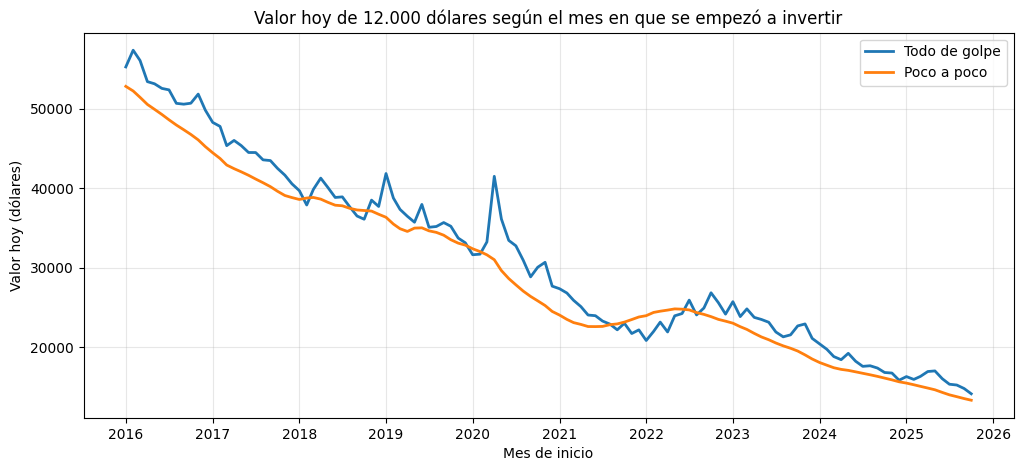

In [8]:
plt.figure(figsize=(12, 5))

# Convierto el mes a fecha para que el eje x se vea bien
# to_timestamp() pasa el periodo (2016-01) a una fecha normal
meses = simulaciones["mes_inicio"].dt.to_timestamp()

# Dibujo las dos líneas
plt.plot(meses, simulaciones["todo_de_golpe"], label="Todo de golpe", linewidth=2)
plt.plot(meses, simulaciones["poco_a_poco"], label="Poco a poco", linewidth=2)

plt.title("Valor hoy de 12.000 dólares según el mes en que se empezó a invertir")
plt.xlabel("Mes de inicio")
plt.ylabel("Valor hoy (dólares)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Las dos líneas bajan de izquierda a derecha porque cuanto más tarde empiezas, menos tiempo lleva el dinero invertido.

Van casi pegadas, con la de todo de golpe normalmente un poco por encima. Solo se cruzan en algunos tramos, que son los meses anteriores a las caídas.

### La diferencia entre las dos estrategias

Aquí se ve la resta de las dos: si la barra va hacia arriba gana todo de golpe, y si va hacia abajo gana poco a poco.

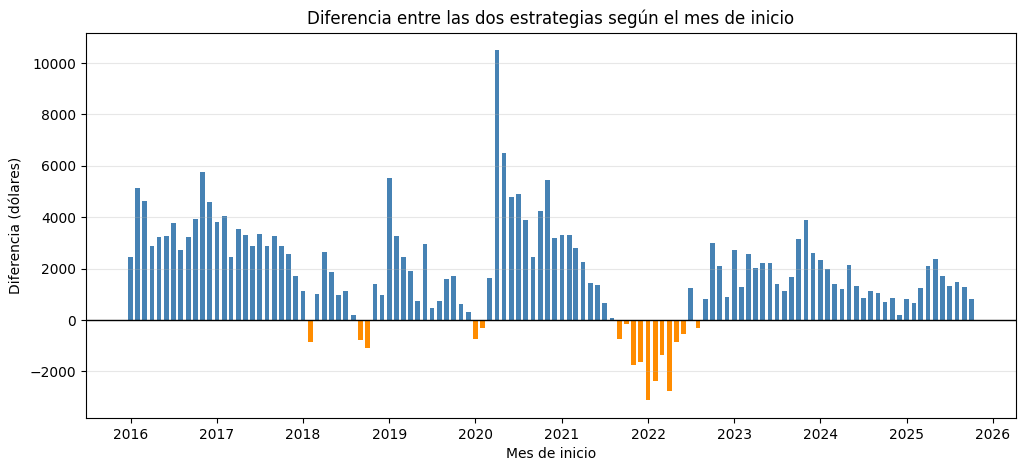

In [9]:
plt.figure(figsize=(12, 5))

# Pinto cada barra de un color según quién gane
# Si la diferencia es positiva gana todo de golpe (azul), si no, poco a poco (naranja)
colores = ["steelblue" if d > 0 else "darkorange" for d in simulaciones["diferencia"]]

# Dibujo las barras
plt.bar(meses, simulaciones["diferencia"], width=20, color=colores)

# Línea horizontal en el 0 para separar los dos lados
plt.axhline(0, color="black", linewidth=1)

plt.title("Diferencia entre las dos estrategias según el mes de inicio")
plt.xlabel("Mes de inicio")
plt.ylabel("Diferencia (dólares)")
plt.grid(alpha=0.3, axis="y")
plt.show()

Este gráfico resume todo el notebook. Casi todas las barras van hacia arriba, y las pocas que van hacia abajo están agrupadas en 2018, 2020 y 2022, que son los momentos anteriores a las caídas grandes.

También se ve que las barras de arriba llegan mucho más alto que las de abajo: cuando gana todo de golpe, gana por mucha más diferencia.

## 8. Guardo los resultados

Guardo la tabla de las simulaciones en Data/Processed, para usarla después en Power BI.

In [10]:
# Convierto el mes a texto para que se guarde bien en el CSV
# astype(str) pasa el periodo (2016-01) a texto
simulaciones["mes_inicio"] = simulaciones["mes_inicio"].astype(str)

# Guardo la tabla
simulaciones.to_csv(RUTA_PROCESSED + "simulaciones.csv", index=False)

print("Guardado:", simulaciones.shape)
simulaciones.head()

Guardado: (118, 5)


,mes_inicio,todo_de_golpe,poco_a_poco,gana,diferencia
0,2016-01,55266.151673,52821.022035,Todo de golpe,2445.129639
1,2016-02,57369.475835,52239.383390,Todo de golpe,5130.092445
2,2016-03,56077.944827,51440.393894,Todo de golpe,4637.550933
3,2016-04,53414.824277,50547.103014,Todo de golpe,2867.721263
4,2016-05,53145.133853,49930.531284,Todo de golpe,3214.602568


In [11]:
# Cuento en cuántos meses ha ganado cada estrategia
print(simulaciones["gana"].value_counts())
print()
print("Total de meses simulados:", len(simulaciones))

gana
Todo de golpe    102
Poco a poco       16
Name: count, dtype: int64

Total de meses simulados: 118


## 9. Resumen

Invertir todo de golpe gana en 101 de los 117 meses probados, un 86,3 % de las veces, y de media saca 1.886 dólares de ventaja sobre 12.000 invertidos.

Cuando gana, gana por mucho (hasta 10.427 dólares), y cuando pierde, pierde poco (como máximo 3.102).

Los 16 meses en que gana invertir poco a poco son todos anteriores a una caída: finales de 2021 y 2022, 2018 y principios de 2020.

Así que invertir poco a poco no sirve para ganar más, sino para protegerse: de media ganas menos, pero si entras justo antes de una caída el golpe es mucho más suave. Y como no se sabe cuándo va a venir una caída, es una decisión de cuánto riesgo quieres asumir.

La simulación está hecha en dólares, que es la moneda del S&P 500. El cambio euro-dólar afectaría al resultado final, pero no a la comparación entre las dos estrategias.

He guardado la tabla simulaciones.csv en Data/Processed.